# 04 · Rolling-Window Pressure & Release (strategy guide, Variant B)

Source: `Global_Rolling_Window_Trading_Strategy_Guide.docx` (v1.0, 15 Nov 2026). The guide's
China A-share mechanism (10-day +100% / 30-day +200% cumulative-deviation thresholds) has **no US
equivalent** — NYSE/Nasdaq LULD is a 5-minute band — so we implement the **global statistical
variant** only and treat "release" purely as a feature. Arm D (regulatory events) is not applicable.

Indicators (Section 3), benchmark B = SPY:

* `D(t,L) = 100·(P_t/P_{t-L} − B_t/B_{t-L})` (percentage points)
* `M(t,W) = max_{L≤W} D(t,L)` for W = 10, 20
* flat-path release `Release(j) = M(t,W) − max(0, M(t,W−j))` — price and benchmark frozen at t,
  calendar advanced j sessions (closed form, so no future data enters)

Setup (Section 4 research defaults): 20-session median dollar volume ≥ $10m, prior 20d relative
strength top decile, 3–8 sessions since the impulse high, pullback < 2 ATR, then confirmation:
close > previous 5-session high, close in the top 25% of the day's range, volume ≥ 1.5× median.


In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3})
from driftrev import config, store, artifacts, dataset, features, models, simulate, analysis, pipeline
print("data dir:", config.DATA_DIR)

data dir: /Users/mac/Documents/New project/stock-data-analysis/project/data


In [2]:
events = store.read_table("events"); ml, feats = dataset.prepare(events)
bo = ml[ml.event_family == "momentum_breakout"]
print(f"momentum_breakout events: {len(bo):,}  | arm A {int(bo.arm_a.sum()):,}  arm B {int(bo.arm_b.sum()):,}  arm C {int(bo.arm_c.sum()):,}")
bo[["rw_dev_20", "rw_max_dev_20", "rw_best_lag_20", "rw_release_20_1", "rw_release_20_3", "rw_release_20_5",
    "rw_days_since_high", "rw_pullback_atr", "rw_volume_mult_med", "rw_prior_strength"]].describe().round(2)

momentum_breakout events: 103,213  | arm A 103,213  arm B 860  arm C 531


,rw_dev_20,rw_max_dev_20,rw_best_lag_20,rw_release_20_1,rw_release_20_3,rw_release_20_5,rw_days_since_high,rw_pullback_atr,rw_volume_mult_med,rw_prior_strength
count,103213.00,103213.00,103213.00,103213.00,103213.00,103213.00,103213.00,103213.00,103213.00,103213.00
mean,15.10,17.67,16.40,0.69,2.08,3.46,3.19,3.01,1.32,0.95
std,14.34,15.75,4.54,2.10,4.14,5.63,4.76,1.14,1.00,0.03
min,-24.21,-0.52,1.00,-0.52,-0.52,-0.52,0.00,0.23,0.00,0.90
25%,7.69,9.36,15.00,0.00,0.00,0.00,0.00,2.19,0.88,0.93
50%,12.24,14.26,18.00,0.00,0.52,1.77,0.00,2.82,1.12,0.95
75%,19.03,21.77,20.00,0.52,2.66,4.67,6.00,3.63,1.49,0.98
max,1555.00,1913.03,20.00,108.81,151.76,233.83,19.00,11.34,66.35,1.00


### Worked example: one Arm-C setup (window math on real prices)

CCI 2026-11-04 | M(t,20) = 34.9 pp, best lag 20, Release(3) = 16.9 pp


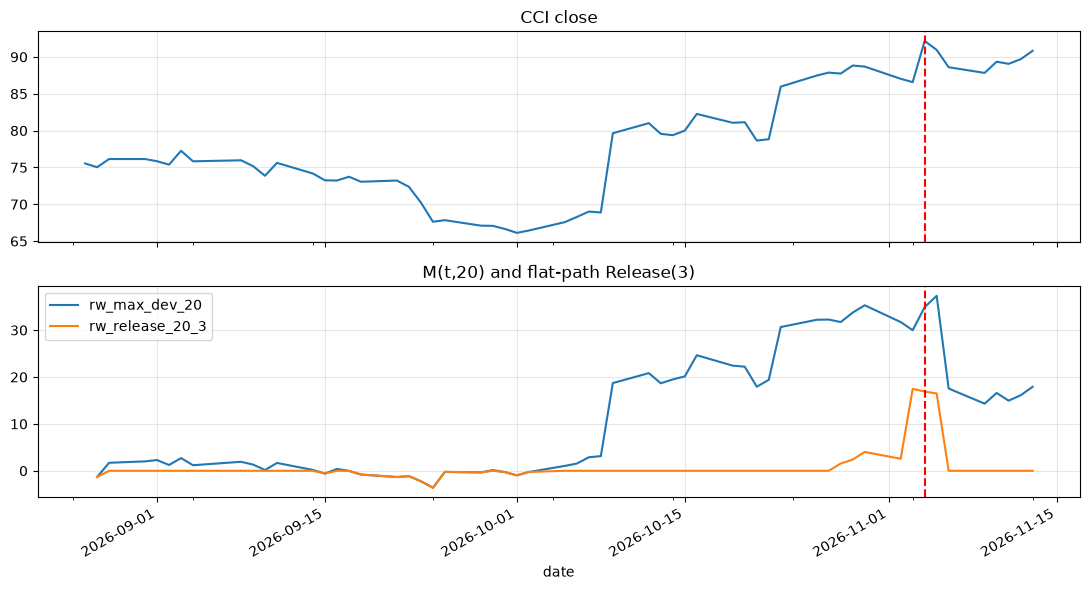

In [3]:
from driftrev import rolling_window as rw, prices
ex = bo[bo.arm_c == 1].sort_values("date").iloc[-1]
px = prices.load_prices([ex.ticker], start=str((ex.date - pd.Timedelta(days=70)).date()))
spy = prices.load_market(); spy = spy[spy.ticker == "SPY"].set_index("date")["close"]
px = px.set_index("date"); b = spy.reindex(px.index)
wf = rw.window_features(px["close"].reset_index(drop=True), b.reset_index(drop=True)); wf.index = px.index
print(ex.ticker, ex.date.date(), "| M(t,20) = %.1f pp, best lag %d, Release(3) = %.1f pp" % (ex.rw_max_dev_20, ex.rw_best_lag_20, ex.rw_release_20_3))
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
px["close"].plot(ax=ax[0], title=f"{ex.ticker} close"); ax[0].axvline(ex.date, color="r", ls="--")
wf[["rw_max_dev_20", "rw_release_20_3"]].plot(ax=ax[1], title="M(t,20) and flat-path Release(3)"); ax[1].axvline(ex.date, color="r", ls="--")
plt.tight_layout(); plt.show()

### Four-arm comparison (Section 9.1) — event level, with bootstrap 95% CI of the mean 10-day return

In [4]:
arms = artifacts.load_frame("guide_arms.parquet"); arms.round(4)

,arm,sample,n,hit_rate_2pct,mean_10d,ci_low,ci_high,mean_10d_vs_spy
0,arm_a,all_years,102818,0.3676,0.0026,0.0021,0.0032,-0.0007
1,arm_b,all_years,857,0.3606,0.0023,-0.0040,0.0086,-0.0022
2,arm_c,all_years,530,0.3434,0.0007,-0.0068,0.0086,-0.0041
3,arm_b_without_release,all_years,327,0.3884,0.0049,-0.0042,0.0140,0.0008
4,arm_a,test,27252,0.3951,0.0068,0.0056,0.0080,0.0020
5,arm_b,test,199,0.3869,0.0081,-0.0052,0.0234,0.0024
6,arm_c,test,117,0.4017,0.0158,-0.0032,0.0353,0.0109
7,arm_b_without_release,test,82,0.3659,-0.0030,-0.0231,0.0146,-0.0096


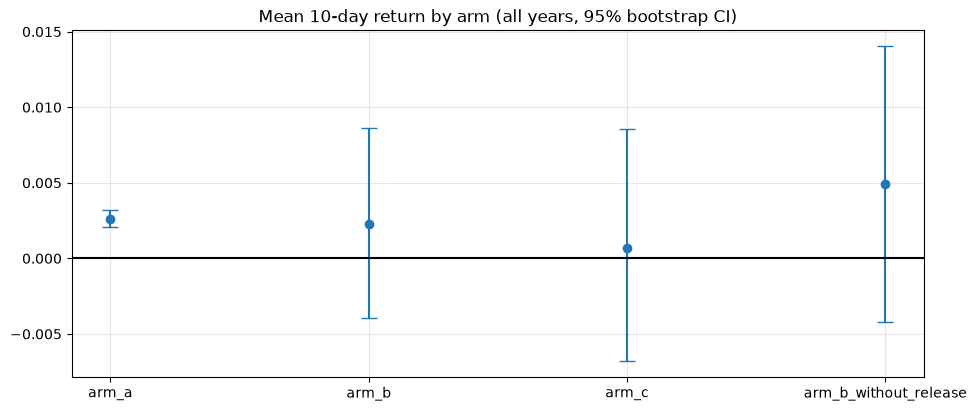

In [5]:
a = arms[arms["sample"] == "all_years"].set_index("arm")
plt.errorbar(a.index, a.mean_10d, yerr=[a.mean_10d - a.ci_low, a.ci_high - a.mean_10d], fmt="o", capsize=6)
plt.axhline(0, color="k"); plt.title("Mean 10-day return by arm (all years, 95% bootstrap CI)"); plt.show()

### Same execution & risk framework for every arm (Sections 6–7): exact simulations on TEST

In [6]:
metrics = artifacts.load_metrics()
g = [s for s in metrics["strategies"] if s["name"].startswith("guide_")]
pd.DataFrame([{**{k: s[k] for k in ("name", "cagr", "sharpe", "max_drawdown", "n_trades")},
               **{k: s["report_card"].get(k) for k in ("fill_rate", "avg_r_multiple", "profit_factor", "win_rate",
                                                         "top5_profit_share", "beta_vs_spy", "mean_ret_ci95")}} for s in g]).round(3)

,name,cagr,sharpe,max_drawdown,n_trades,fill_rate,avg_r_multiple,profit_factor,win_rate,top5_profit_share,beta_vs_spy,mean_ret_ci95
0,guide_armA_momentum_breakout,0.016,0.250,-0.077,611,0.022,-0.001,1.054,0.450,1.616,0.217,"[-0.006001676230720991, 0.011324083466879572]"
1,guide_armB_plus_consolidation,0.011,0.297,-0.055,169,0.837,0.041,1.105,0.533,1.826,0.082,"[-0.008514944352736057, 0.012528579113011607]"
2,guide_armC_plus_window_release,0.017,0.560,-0.038,106,0.898,0.094,1.275,0.547,1.139,0.048,"[-0.006797126735048199, 0.01860170803657041]"
3,guide_model_breakout_R,0.022,0.668,-0.033,62,0.155,0.192,1.512,0.532,1.363,0.016,"[-0.018367912027121683, 0.05724547226198793]"
4,guide_model_all_events_R,0.026,0.780,-0.032,93,0.086,0.134,1.417,0.527,1.071,0.040,"[-0.002946602076892615, 0.05141569442867986]"


### Key causal test and parameter sensitivity

In [7]:
print(json.dumps(metrics["guide"], indent=1))
sens = artifacts.load_frame("guide_sensitivity.parquet")
sens.pivot_table(index=["release_col", "threshold_pp"], columns="sample", values=["n", "mean_10d", "hit_rate_2pct"]).round(4)

{
 "key_causal_test": "Does Arm C (+ rolling-window release) beat Arm B (momentum + consolidation)?",
 "verdict": "release does NOT add value -> discard the rollover factor (guide Section 9 rule) | Sharpe C > B; all-years mean C <= B; test mean C > B; sign flips across release thresholds",
 "evidence": {
  "arm_b_all_years_mean_10d": 0.002305811060865792,
  "arm_b_test_mean_10d": 0.008097033715723494,
  "arm_c_all_years_mean_10d": 0.0006855557877908068,
  "arm_c_test_mean_10d": 0.015842604122960208,
  "sensitivity_sign_stable": false
 },
 "arm_d": "not applicable: US exchanges have no cumulative-deviation threshold (LULD is a 5-minute band)",
 "arms_sharpe": {
  "guide_armA_momentum_breakout": 0.24960713569639392,
  "guide_armB_plus_consolidation": 0.29681457030683916,
  "guide_armC_plus_window_release": 0.5604113620779897
 }
}


hit_rate_2pct          mean_10d                 n       
sample                           all_years    test all_years    test all_years   test
release_col     threshold_pp                                                         
rw_release_10_3 0.0                 0.3744  0.3786    0.0062  0.0119     454.0  103.0
                2.0                 0.3618  0.3684    0.0078  0.0258     199.0   38.0
                5.0                 0.3438  0.4615    0.0024  0.0255      64.0   13.0
                10.0                0.3478  0.5000    0.0339  0.1369      23.0    4.0
rw_release_20_1 0.0                 0.3216  0.4688   -0.0002  0.0294     283.0   64.0
                2.0                 0.3750  0.5000    0.0003  0.0328      88.0   18.0
                5.0                 0.4194  0.3333   -0.0011  0.0038      31.0    6.0
                10.0                0.5000  1.0000    0.0345  0.2005       6.0    1.0
rw_release_20_3 0.0                 0.3434  0.4017    0.0007  0.0158     530.0  117.0
                2.0                 0.3630  0.3944    0.0011  0.0164     292.0   71.0
                5.0                 0.3652  0.3704   -0.0025  0.0204     115.0   27.0
                10.0                0.3939  0.2500   -0.0185 -0.0164      33.0    8.0
rw_release_20_5 0.0                 0.3472  0.3933    0.0024  0.0145     651.0  150.0
                2.0                 0.3655  0.3796    0.0037  0.0137     446.0  108.0
                5.0                 0.3429  0.3793    0.0003  0.0130     210.0   58.0
                10.0                0.3784  0.2778   -0.0190 -0.0374      74.0   18.0

### Cost stress test (1× / 2× / 3× the 15 bps one-way cost)

In [8]:
artifacts.load_frame("cost_stress.parquet").pivot_table(index="strategy", columns="cost_mult", values="cagr").round(4)

cost_mult,1.0,2.0,3.0
strategy,,,
all_events_unconditional,0.4061,0.3040,0.2093
guide_armA_momentum_breakout,0.0164,-0.0152,-0.0298
guide_armB_plus_consolidation,0.0114,-0.0016,-0.0144
guide_armC_plus_window_release,0.0169,0.0084,0.0000
guide_model_all_events_R,0.0264,0.0220,0.0175
guide_model_breakout_R,0.0216,0.0182,0.0147


### Interpretation

The guide's own rule decides: *if adding window release does not materially improve risk-adjusted
results over the same momentum + consolidation + breakout strategy, discard the rollover factor
rather than rebranding ordinary momentum.* The verdict printed above is computed, not hand-written;
the README reports it with the numbers. The release features stay in the ML feature set either way,
so the model can use (or ignore) them — their importance is visible in notebook 02.
